# Preprocessing EV Battery Health untuk MLP

**Proyek JST: input yang siap dipelajari, dengan pencegahan kebocoran data**

Notebook ini menerapkan keputusan berbasis EDA menjadi pipeline yang dapat dipakai ulang untuk data baru. Parameter dipelajari hanya dari train, lalu dibekukan untuk validation/test.

Target: estimasi `state_of_health_pct` saat observasi pada baterai baru. Split grup tetap 1.820 / 390 / 390 baterai. **Tidak ada training MLP atau pemilihan resep berdasarkan skor model dalam notebook ini.**

Preprocessing membantu optimasi dan kualitas input, tetapi tidak menjamin bebas overfitting/underfitting. Klaim tersebut memerlukan learning curves train–validation dan eksperimen kapasitas/regularisasi.

## 1. Input, sumber keputusan, dan lingkungan

Keputusan mengikuti `configs/feature_contract.json`, EDA train sebelumnya, dan resep eksplisit pada `configs/preprocessing.json`. CSV asli, kontrak fitur awal, dan manifest baterai tidak ditimpa. Tidak menggabungkan subset untuk imputasi atau memulihkan metadata per baterai.

Artefak numerik/fitted pipeline disimpan lokal; laporan, parameter, dan nama fitur dapat dibagikan lewat Git.

In [1]:
from pathlib import Path
import sys, json, hashlib, subprocess
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Image
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/preprocessing.py').is_file()), None)
if ROOT is None:
    raise RuntimeError('Jalankan dari root proyek atau folder notebooks.')
if str(ROOT) not in sys.path:
    sys.path.insert(0,str(ROOT))
from src.preprocessing import run_preprocessing, load_prepared_split, TARGET, FORBIDDEN
pd.set_option('display.max_columns',12)
pd.set_option('display.max_colwidth',85)
pd.set_option('display.precision',6)
result = run_preprocessing(ROOT)
train = result['splits']['train']
variants = result['variants']
def show(name):
    display(Image(filename=str(result['output']/name),width=1100))
print('Semua fit pada train saja; validation/test hanya transform.')
display(result['summary'])

Semua fit pada train saja; validation/test hanya transform.


,recipe,split,rows,batteries,raw_features,input_neurons,numeric_missing_after,finite,dtype
0,baseline_standard,train,34929,1820,21,67,0,True,float32
1,baseline_standard,validation,7499,390,21,67,0,True,float32
2,baseline_standard,test,7572,390,21,67,0,True,float32
3,log_sensor_caps,train,34929,1820,21,67,0,True,float32
4,log_sensor_caps,validation,7499,390,21,67,0,True,float32
5,log_sensor_caps,test,7572,390,21,67,0,True,float32
6,compact_log_sensor_caps,train,34929,1820,19,63,0,True,float32
7,compact_log_sensor_caps,validation,7499,390,19,63,0,True,float32
8,compact_log_sensor_caps,test,7572,390,19,63,0,True,float32


## 2. Tiga resep: acuan dan ablation yang belum diperingkat

- **baseline_standard:** seluruh 21 fitur sah; median + indikator missing; one-hot; standardisasi numerik. Ini default awal yang paling sederhana untuk acuan.
- **log_sensor_caps:** fitur sama, signed log1p pada lima fitur berekor kanan dan cap terarah pada tiga sensor memakai quantile train 0,5% / 99,5%.
- **compact_log_sensor_caps:** mengeluarkan throughput dan suhu puncak yang redundan, tetap mempertahankan umur serta siklus.

Full vs log/cap adalah perbandingan gabungan dua perubahan; tidak mengisolasi efek log dan cap sendiri-sendiri. Compact vs log/cap menguji pengurangan dua fitur. Jika perlu mengetahui efek masing-masing langkah, pecah eksperimen saat training nanti. Tidak menyebut resep alternatif sebagai pemenang sebelum ada hasil validation.

In [2]:
specs = []
for name,spec in result['settings']['recipes'].items():
    prep = variants[name]['preprocessor']
    specs.append({'recipe':name,'raw_features':len(prep.required_columns),'input_neurons':prep.n_features_out_,
                  'dropped':', '.join(spec['drop_features']) or 'Tidak ada',
                  'log':', '.join(spec['log_features']) or 'Tidak ada',
                  'caps':', '.join(spec['clip_features']) or 'Tidak ada'})
display(pd.DataFrame(specs))

,recipe,raw_features,input_neurons,dropped,log,caps
0,baseline_standard,21,67,Tidak ada,Tidak ada,Tidak ada
1,log_sensor_caps,21,67,Tidak ada,"cycle_count, total_energy_throughput_kwh, avg_daily_distance_km, altitude_m, serv...","avg_charging_power_kw, avg_ambient_temp_c, peak_temp_during_fast_charge_c"
2,compact_log_sensor_caps,19,63,"total_energy_throughput_kwh, peak_temp_during_fast_charge_c","cycle_count, avg_daily_distance_km, altitude_m, service_count","avg_charging_power_kw, avg_ambient_temp_c"


## 3. Skema ketat dan pencegahan leakage

capacity_fade_pct, tiga target alternatif, ID, tanggal mentah, serta empat kandidat proxy sensor tidak masuk pipeline utama. Input harus memiliki kolom yang tepat; urutannya boleh berubah karena pipeline menyusun ulang berdasarkan nama. Kolom hilang atau tambahan ditolak agar target tidak terselip.

Kategori tidak diberi angka ordinal buatan. Tidak melakukan group fill dari observasi masa depan atau dari holdout.

In [3]:
base = variants['baseline_standard']['preprocessor']
for name,entry in variants.items():
    assert set(entry['preprocessor'].required_columns).isdisjoint(FORBIDDEN)
    assert entry['preprocessor'].fit_rows_ == 34929
print('PASS: ketiga resep tidak memuat ID, target, tanggal, atau proxy yang dilarang.')
display(pd.DataFrame({'input_column':base.required_columns}))

PASS: ketiga resep tidak memuat ID, target, tanggal, atau proxy yang dilarang.


,input_column
0,pack_capacity_kwh
1,battery_age_days
2,cycle_count
3,avg_daily_distance_km
4,avg_charging_power_kw
5,fast_charge_ratio
6,avg_depth_of_discharge_pct
7,avg_state_of_charge_pct
8,charge_cycles_per_month
9,total_energy_throughput_kwh


## 4. Pembersihan yang tidak menghapus baris

Nilai nonnumerik/tak hingga dan pelanggaran definisi sederhana dijadikan missing, disertai hitungan diagnostik. Contoh: rasio di luar 0–1, persentase di luar 0–100, recall selain 0/1, dan hitungan servis negatif/pecahan. Altitude negatif dapat sah sehingga dipertahankan.

Nilai yang masih valid secara definisi tidak otomatis dianggap salah hanya karena jauh dari median. Raw source tidak diubah. Tidak memaksa counter monoton, membuat tanggal fiktif, atau membuang SOH rendah.

In [4]:
display(pd.DataFrame({name:entry['preprocessor'].invalid_counts_train_ for name,entry in variants.items()}).fillna('tidak dipakai'))
assert all(sum(entry['preprocessor'].invalid_counts_train_.values())==0 for entry in variants.values())
print('Pada CSV train saat ini tidak ditemukan nilai yang melanggar aturan cleaning tersebut.')

,baseline_standard,log_sensor_caps,compact_log_sensor_caps
pack_capacity_kwh,0,0,0.0
battery_age_days,0,0,0.0
cycle_count,0,0,0.0
avg_daily_distance_km,0,0,0.0
avg_charging_power_kw,0,0,0.0
fast_charge_ratio,0,0,0.0
avg_depth_of_discharge_pct,0,0,0.0
avg_state_of_charge_pct,0,0,0.0
charge_cycles_per_month,0,0,0.0
total_energy_throughput_kwh,0,0,tidak dipakai


Pada CSV train saat ini tidak ditemukan nilai yang melanggar aturan cleaning tersebut.


## 5. Missing value: median, indikator, kategori eksplisit

Median numerik berasal dari nilai train terisi, bukan seluruh CSV. Indikator missing disediakan untuk semua numerik dan biner agar missing yang baru muncul saat inferensi tetap dapat direpresentasikan. Kategori kosong memakai `__MISSING__`, bukan modus yang menyamarkan ketidaktersediaan kimia.

Recall flag memakai modus train, tetap 0/1 dan tidak terkena clipping IQR. Indikatornya membedakan nilai imputasi dari observasi asli. Ini menambah input, sehingga manfaat indikator tetap dapat diuji kelak bila perlu.

In [5]:
params = pd.read_csv(result['output']/'baseline_standard_numeric_parameters.csv')
display(params[['feature','median_train_original']])
for c in base.numeric_features:
    assert np.isclose(base.medians_[c],train[c].median())
assert base.binary_modes_['recall_flag'] == train.recall_flag.mode().iloc[0]
print('PASS: median dan modus sesuai train saja.')
probe = train.loc[:,base.required_columns].iloc[[0]].copy()
probe['cycle_count'] = np.nan
probe_X = base.transform(probe)
flag = list(base.get_feature_names_out()).index('missing__cycle_count')
assert probe_X[0,flag] == 1
assert np.isfinite(probe_X).all()
print('Probe missing baru berhasil; ini contoh uji, bukan perubahan dataset.')

,feature,median_train_original
0,pack_capacity_kwh,72.500
1,battery_age_days,418.000
2,cycle_count,372.000
3,avg_daily_distance_km,39.300
4,avg_charging_power_kw,28.600
5,fast_charge_ratio,0.272
6,avg_depth_of_discharge_pct,65.000
7,avg_state_of_charge_pct,67.900
8,charge_cycles_per_month,19.000
9,total_energy_throughput_kwh,24155.300


PASS: median dan modus sesuai train saja.
Probe missing baru berhasil; ini contoh uji, bukan perubahan dataset.


## 6. Encoding kategori dan kategori yang belum pernah terlihat

One-hot membuat satu kolom per kategori tanpa menganggap LFP < NMC atau produsen mempunyai urutan angka. Kategori missing dialokasikan sejak fit, termasuk jika fitur kebetulan lengkap pada train.

Kategori baru saat inferensi dipetakan ke blok all-zero untuk fitur tersebut, dengan dimensi tetap. Ini **berbeda** dari missing yang mempunyai one-hot tersendiri. Pipeline menyediakan diagnostic untuk menghitung kategori baru; tidak mempelajarinya ulang pada validation/test.

In [6]:
display(pd.read_csv(result['output']/'baseline_standard_categories.csv'))
probe = train.loc[:,base.required_columns].iloc[[0,0]].copy().reset_index(drop=True)
probe.loc[0,'chemistry'] = 'NEW_CHEMISTRY_FOR_TEST'
probe.loc[1,'chemistry'] = None
state_before = joblib.hash(base)
X_probe = base.transform(probe)
chem_idx = [i for i,n in enumerate(base.get_feature_names_out()) if n.startswith('cat__chemistry_')]
assert X_probe[0,chem_idx].sum() == 0
assert X_probe[1,chem_idx].sum() == 1
assert joblib.hash(base) == state_before
print('PASS: unknown dan missing berbeda, lebar tetap, parameter tidak berubah.')
display(pd.Series(base.diagnostic(probe)['unknown_categories'],name='unknown_probe').to_frame())

,feature,category,block_index
0,chemistry,LFP,0
1,chemistry,LMO,1
2,chemistry,NCA,2
3,chemistry,NMC,3
4,chemistry,__MISSING__,4
5,manufacturer,Amperion,0
6,manufacturer,CellTech,1
7,manufacturer,GigaWatt Labs,2
8,manufacturer,IonFlux,3
9,manufacturer,NexCell,4


PASS: unknown dan missing berbeda, lebar tetap, parameter tidak berubah.


,unknown_probe
chemistry,1
manufacturer,0
vehicle_model,0
climate_zone,0
bms_firmware_version,0


## 7. Outlier dan long tail: terarah dan dapat dibandingkan

EDA menunjukkan distribusi miring pada siklus, energi, jarak, altitude, dan jumlah servis. Resep alternatif memakai signed log1p: identik log1p pada nilai nonnegatif, tetap sah untuk altitude negatif.

Cap hanya diterapkan pada daya pengisian, suhu lingkungan, serta suhu puncak yang ditetapkan, dengan batas 0,5% / 99,5% dari **train terisi sebelum imputasi**. Tidak menerapkan IQR pada semua fitur atau target. Nilai ekstrem yang valid dapat membawa informasi; cap juga dapat merugikan. Itulah alasan baseline tanpa cap tetap disediakan.

,feature,median_train_original,cap_lower_train,cap_upper_train,signed_log1p,scaler_mean_after_transform_train,scaler_scale_after_transform_train
0,pack_capacity_kwh,72.500,NaN,NaN,False,72.625386,14.069199
1,battery_age_days,418.000,NaN,NaN,False,547.234819,463.060142
2,cycle_count,372.000,NaN,NaN,True,5.712526,1.308864
3,avg_daily_distance_km,39.300,NaN,NaN,True,3.667027,0.751704
4,avg_charging_power_kw,28.600,3.000,92.3,False,31.789018,17.165768
5,fast_charge_ratio,0.272,NaN,NaN,False,0.291768,0.165757
6,avg_depth_of_discharge_pct,65.000,NaN,NaN,False,64.768158,15.361672
7,avg_state_of_charge_pct,67.900,NaN,NaN,False,67.641189,9.809927
8,charge_cycles_per_month,19.000,NaN,NaN,False,20.253194,10.079811
9,total_energy_throughput_kwh,24155.300,NaN,NaN,True,9.890457,1.339541


,baris_train_di_cap_per_fitur
avg_charging_power_kw,175
avg_ambient_temp_c,214
peak_temp_during_fast_charge_c,331


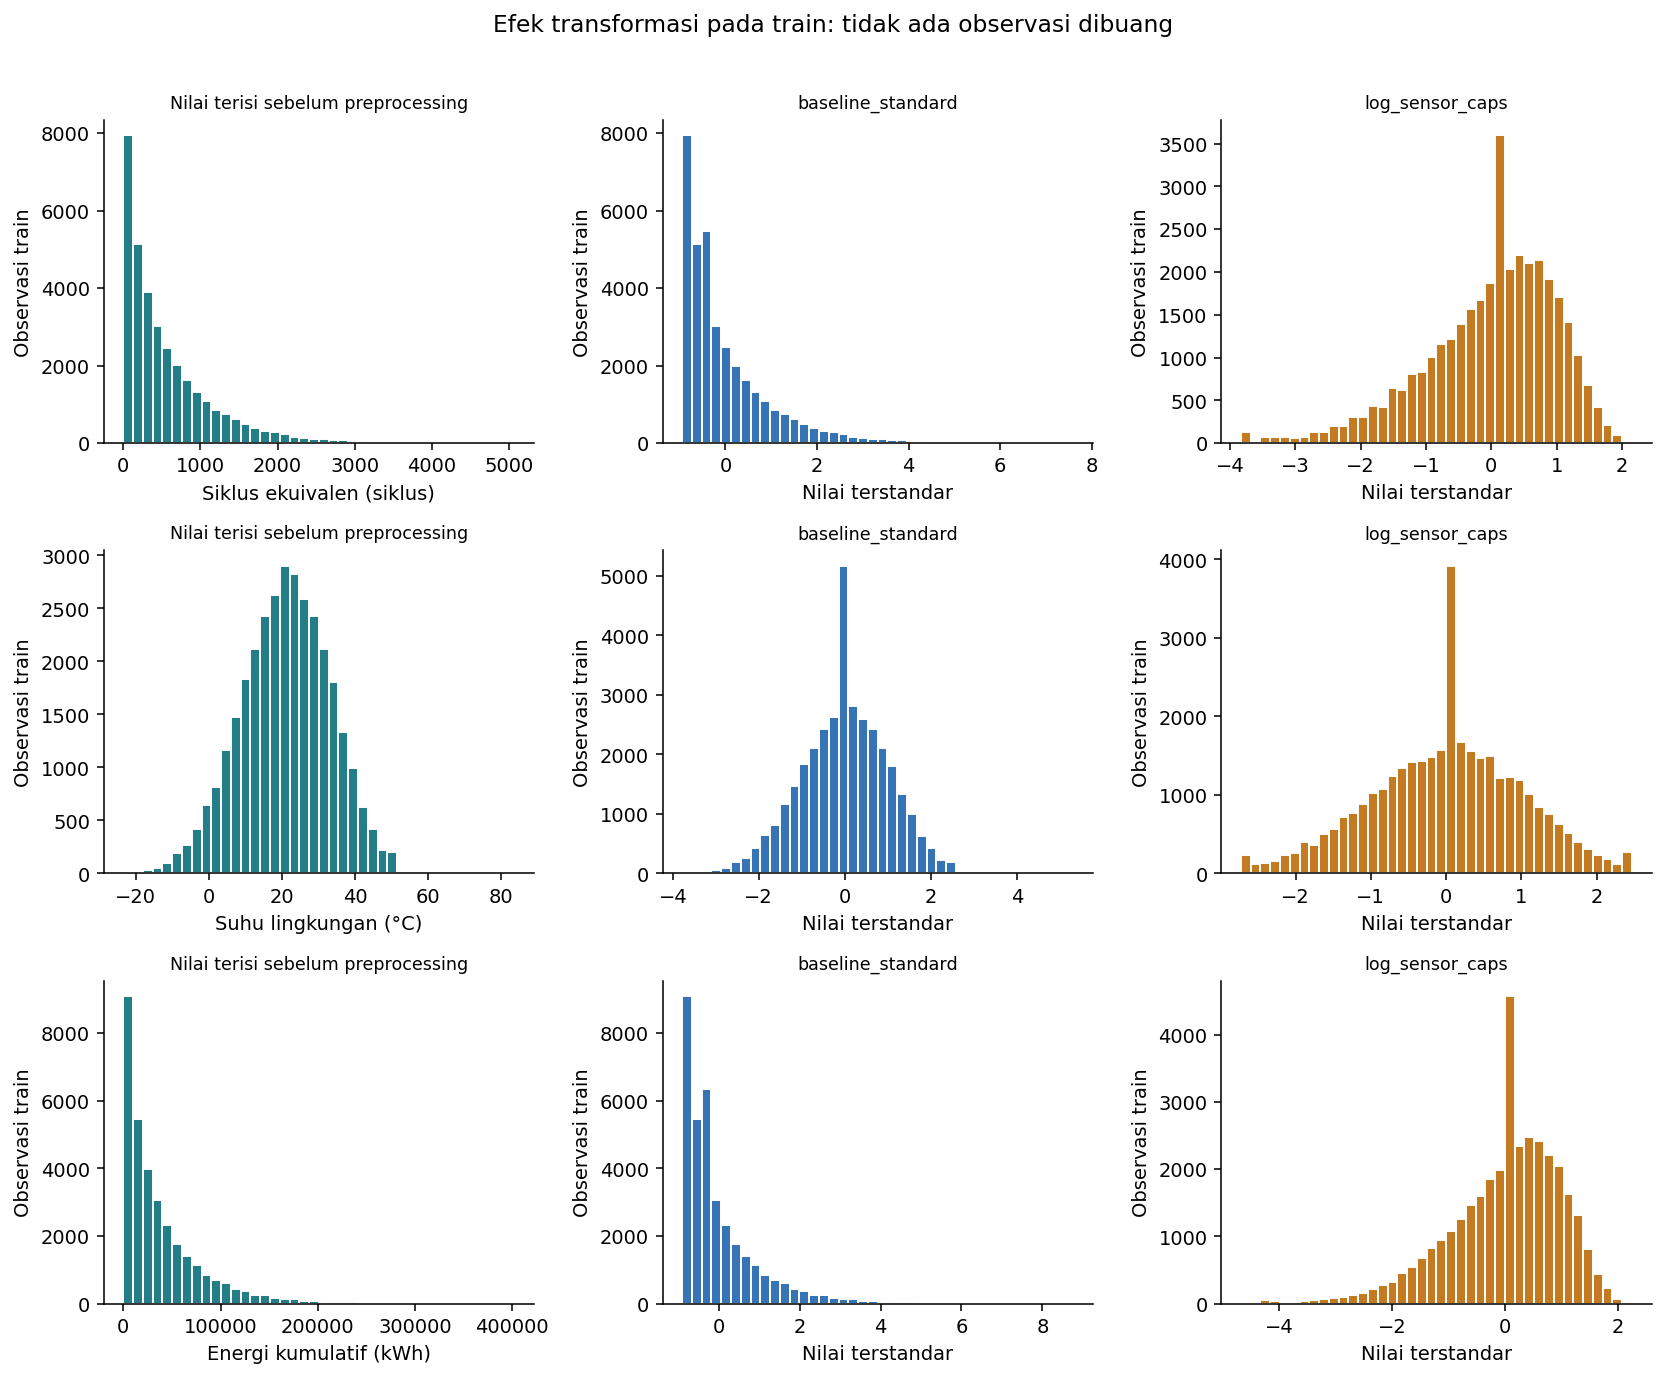

In [7]:
robust = variants['log_sensor_caps']['preprocessor']
display(pd.read_csv(result['output']/'log_sensor_caps_numeric_parameters.csv'))
for c,(low,high) in robust.clip_bounds_.items():
    expected = train[c].quantile([.005,.995]).to_numpy()
    np.testing.assert_allclose([low,high],expected)
display(pd.Series(robust.diagnostic(variants['log_sensor_caps']['train_raw'])['clipped_rows_by_feature'],name='baris_train_di_cap_per_fitur').to_frame())
show('01_before_after_train.png')

**Interpretasi:** log merapatkan ekor panjang tanpa mengubah urutan nilai nonnegatif; cap membatasi pengaruh sensor ekstrem dengan mengorbankan detail di ekor. Spike sekitar median dapat berasal dari imputasi dan ditandai missing indicator. Grafik hanya train dan tidak menunjukkan skor prediksi. Tidak ada observasi dibuang.

## 8. Normalisasi setelah transformasi

Untuk setiap numerik: `(x_transformed − mean_train) / scale_train`. Parameter scaler dipelajari setelah imputasi dan transformasi resep agar konsisten dengan data yang masuk MLP.

Hanya blok numerik distandardisasi. One-hot, biner, dan missing flags tetap 0/1. Memaksa flag sangat langka menjadi unit variance dapat memperbesar nilai aktifnya secara tidak perlu. Validation/test tidak di-fit ulang agar mean/std mereka terlihat seperti train.

,recipe,max_abs_numeric_mean_train,max_abs_std_minus_one_train
0,baseline_standard,1.096395e-08,7.829885e-09
1,log_sensor_caps,2.426617e-08,8.476567e-09
2,compact_log_sensor_caps,2.426617e-08,8.476567e-09


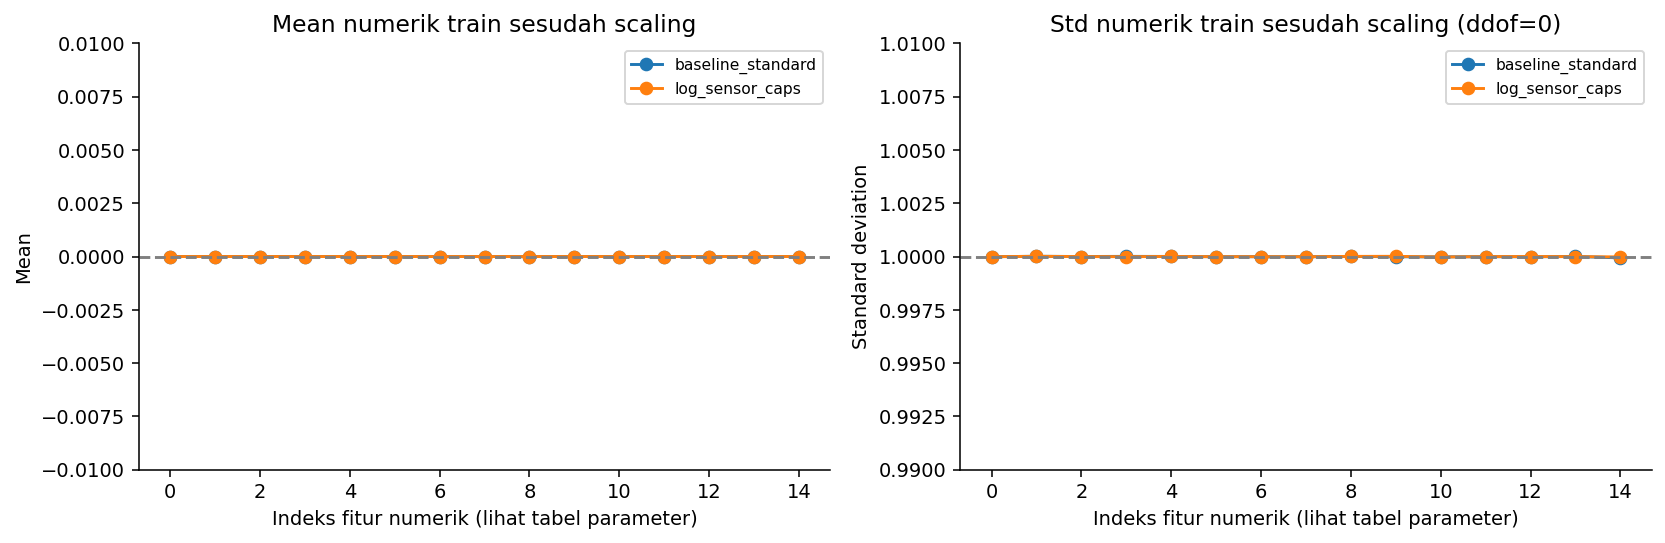

In [8]:
scale_rows = []
for name,entry in variants.items():
    prep = entry['preprocessor']
    numeric = entry['train_X'][:,:len(prep.numeric_features)].astype(np.float64)
    scale_rows.append({'recipe':name,'max_abs_numeric_mean_train':np.abs(numeric.mean(axis=0)).max(),
                       'max_abs_std_minus_one_train':np.abs(numeric.std(axis=0,ddof=0)-1).max()})
    assert np.abs(numeric.mean(axis=0)).max() < 1e-6
    assert np.abs(numeric.std(axis=0,ddof=0)-1).max() < 1e-6
display(pd.DataFrame(scale_rows))
show('02_scaler_train_checks.png')

## 9. Feature selection untuk ablation, bukan kesimpulan final

Compact mengeluarkan throughput (Spearman dengan siklus ≈0,984) dan suhu puncak fast charge (dengan suhu lingkungan ≈0,920). Umur dan siklus dipertahankan karena dapat membawa informasi kalender dan penggunaan berbeda.

Tidak menghapus fitur hanya karena korelasi target rendah. Reduksi fitur berpotensi mengurangi kapasitas yang tidak perlu, tetapi juga dapat menimbulkan underfitting jika informasi yang relevan hilang. Karena itu pilihan akhir harus memakai validation.

,recipe,raw_features,input_neurons,illustrative_parameters_hidden_64_32
0,baseline_standard,21,67,6465
1,log_sensor_caps,21,67,6465
2,compact_log_sensor_caps,19,63,6209


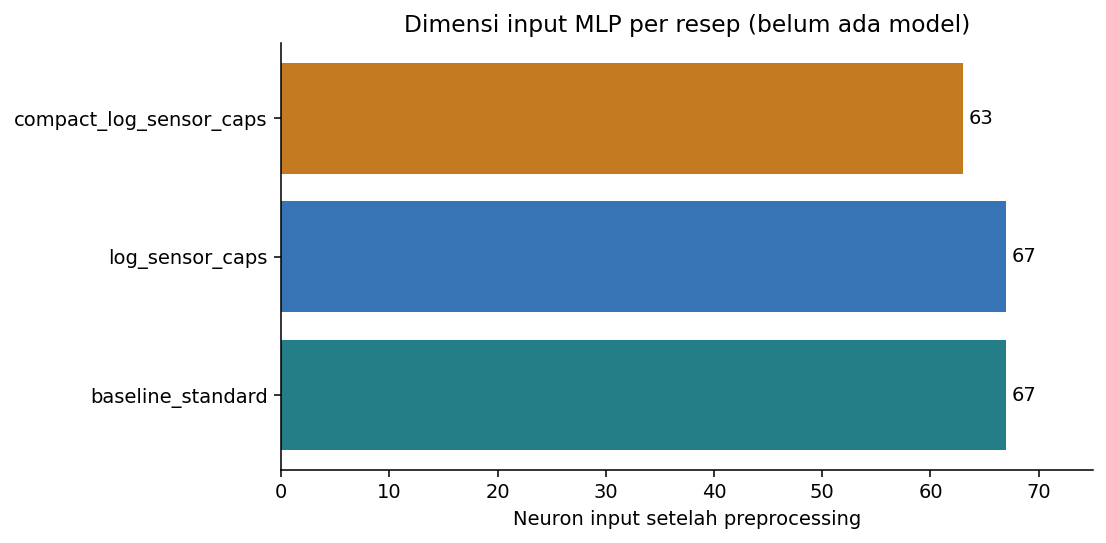

In [9]:
dimensions = []
for name,entry in variants.items():
    prep = entry['preprocessor']; p = prep.n_features_out_
    dimensions.append({'recipe':name,'raw_features':len(prep.required_columns),'input_neurons':p,
                       'illustrative_parameters_hidden_64_32':(p*64+64)+(64*32+32)+(32+1)})
display(pd.DataFrame(dimensions))
show('03_input_dimensions.png')

**Hasil dimensi:** dua versi lengkap menghasilkan 67 input (15 nilai numerik + 15 indikator numerik + 1 biner + 1 indikator biner + 35 one-hot). Compact menghasilkan 63 input karena membuang dua nilai numerik beserta dua indikatornya. Contoh jumlah parameter menggunakan hidden [64,32] hanya ilustrasi; jaringan tersebut belum dilatih.

## 10. Target terstandar dan satuan evaluasi

SOH asli tidak dipotong, diubah menjadi kelas, atau diseimbangkan. StandardScaler target hanya fit y_train. Tujuannya memberi output linear MLP skala sekitar nol saat belajar. `y_scaled` disimpan untuk training, `y_original` tetap tersedia untuk evaluasi.

Prediksi harus dikembalikan ke satuan SOH sebelum MAE/RMSE. Untuk Huber, delta juga harus dijelaskan pada skala target yang dipakai. Penskalaan target bukan jaminan performa lebih baik.

In [10]:
target_scaler = result['target_scaler']
assert np.isclose(target_scaler.mean_[0],train[TARGET].mean())
assert np.isclose(target_scaler.scale_[0],train[TARGET].std(ddof=0))
scaled = target_scaler.transform(train[[TARGET]]).ravel().astype(np.float32)
restored = target_scaler.inverse_transform(scaled.astype(float).reshape(-1,1)).ravel()
max_error = np.max(np.abs(restored-train[TARGET].to_numpy()))
assert max_error < 1e-5
display(pd.Series({'mean_target_train':target_scaler.mean_[0], 'scale_target_train':target_scaler.scale_[0],
                   'roundtrip_max_error_pp':max_error}).to_frame('nilai'))
print('Tidak ada SMOTE, sampling ulang, clipping y, atau penghapusan SOH rendah.')

,nilai
mean_target_train,92.918747
scale_target_train,7.192673
roundtrip_max_error_pp,0.000002


Tidak ada SMOTE, sampling ulang, clipping y, atau penghapusan SOH rendah.


## 11. Artefak siap pakai dan keselarasan ID/X/y

Array setiap resep mempunyai X float32, y_scaled, y_original, ID observasi/baterai, urutan fitur, serta identitas state pipeline. Helper memeriksa kesesuaian resep/split/state agar data tidak tercampur dengan pipeline dari run lain.

Validation/test di sini hanya diperiksa untuk kesiapan input dan keselarasan baris. Tidak menghitung distribusi target, loss, skor, atau mengubah resep dari holdout. Semua fit sudah selesai sebelum transform holdout.

In [11]:
for recipe in variants:
    for split,raw in result['splits'].items():
        data,bundle = load_prepared_split(recipe,split,ROOT)
        assert data['X'].dtype == np.float32
        assert data['X'].shape == (len(raw),len(bundle['feature_names']))
        assert np.isfinite(data['X']).all() and np.isfinite(data['y_scaled']).all()
        np.testing.assert_array_equal(data['observation_id'],raw.observation_id.to_numpy(dtype=str))
        np.testing.assert_array_equal(data['battery_id'],raw.battery_id.to_numpy(dtype=str))
        np.testing.assert_array_equal(data['y_original'],raw[TARGET].to_numpy())
        assert not set(bundle['required_columns']).intersection(FORBIDDEN)
print('PASS: sembilan array split/resep valid, ID dan target selaras, tidak ada kebocoran kolom.')
display(result['checks'])

PASS: sembilan array split/resep valid, ID dan target selaras, tidak ada kebocoran kolom.


,recipe,check,result
0,baseline_standard,transform_state_unchanged,PASS
1,baseline_standard,all_split_float32_finite_and_same_width,PASS
2,baseline_standard,target_inverse_max_error_pp,0.000001712
3,baseline_standard,serialization_exact_first_16_rows,PASS
4,log_sensor_caps,transform_state_unchanged,PASS
5,log_sensor_caps,all_split_float32_finite_and_same_width,PASS
6,log_sensor_caps,target_inverse_max_error_pp,0.000001712
7,log_sensor_caps,serialization_exact_first_16_rows,PASS
8,compact_log_sensor_caps,transform_state_unchanged,PASS
9,compact_log_sensor_caps,all_split_float32_finite_and_same_width,PASS


## 12. Uji perilaku untuk kasus baru

Pengujian mencakup: statistik dari train saja, state tidak berubah setelah transform, kategori/missing baru, nilai invalid, negative altitude yang sah, urutan kolom, penolakan kolom bocor, numeric/biner seluruhnya missing pada fit, target opsional yang tidak memengaruhi fit fitur, dan serialisasi.

Dataset kecil buatan dalam test hanya untuk memeriksa perilaku. Tidak digunakan mengganti dataset atau sebagai hasil eksperimen model.

In [12]:
checked = subprocess.run([sys.executable,'-m','unittest','discover','-s','tests','-v'],cwd=ROOT,capture_output=True,text=True)
print(checked.stdout + checked.stderr)
assert checked.returncode == 0, 'Perbaiki kegagalan sebelum memakai artefak preprocessing.'

test_all_missing_numeric_or_binary_requires_explicit_decision (test_preprocessing.PreprocessingTests.test_all_missing_numeric_or_binary_requires_explicit_decision) ... ok
test_category_missing_allocated_even_when_train_has_no_missing (test_preprocessing.PreprocessingTests.test_category_missing_allocated_even_when_train_has_no_missing) ... ok
test_clipping_and_signed_log_use_frozen_bounds_and_keep_negative_altitude (test_preprocessing.PreprocessingTests.test_clipping_and_signed_log_use_frozen_bounds_and_keep_negative_altitude) ... ok
test_invalid_values_become_missing_and_original_is_unchanged (test_preprocessing.PreprocessingTests.test_invalid_values_become_missing_and_original_is_unchanged) ... ok
test_loader_rejects_mixed_fitted_pipeline_and_array (test_preprocessing.PreprocessingTests.test_loader_rejects_mixed_fitted_pipeline_and_array) ... ok
test_loader_rejects_target_with_wrong_row_count (test_preprocessing.PreprocessingTests.test_loader_rejects_target_with_wrong_row_count) ... o

## 13. Provenance dan batas cross-validation

CSV sumber dan split dikunci ke hash audit. Provenance mencatat daftar ID train yang dipakai untuk fit, versi paket, source preprocessing, dan konfigurasi. Preprocessing tidak memodifikasi laporan/artefak EDA sebelumnya.

**Penting untuk cross-validation:** array precomputed sudah memakai statistik seluruh train dan hanya cocok untuk split train/validation/test tetap ini. Untuk CV di dalam train, buat/clone pipeline dan target scaler baru per fold lalu fit hanya fold-train. Jangan memakai array yang sudah dinormalisasi seluruh train untuk fold-validation.

In [13]:
meta = result['provenance']
assert meta['fit_split'] == 'train' and meta['fit_rows'] == 34929 and meta['fit_batteries'] == 1820
assert meta['dataset_sha256'] == hashlib.sha256((ROOT/'data/raw/ev_battery_health.csv').read_bytes()).hexdigest()
assert meta['split_manifest_sha256'] == hashlib.sha256((ROOT/'data/splits/battery_split.csv').read_bytes()).hexdigest()
assert meta['source_sha256'] == hashlib.sha256((ROOT/'src/preprocessing.py').read_bytes()).hexdigest()
assert meta['fit_observation_ids_sha256'] == hashlib.sha256(chr(10).join(train.observation_id).encode()).hexdigest()
display(pd.Series(meta['packages'],name='versi').to_frame())
print('PASS: seluruh parameter/artefak terikat pada sumber, train, dan kode yang tercatat.')

,versi
numpy,2.2.5
pandas,2.3.2
scikit-learn,1.7.2
joblib,1.5.2
matplotlib,3.10.6


PASS: seluruh parameter/artefak terikat pada sumber, train, dan kode yang tercatat.


## 14. Apa artinya untuk overfitting dan underfitting?

| Risiko | Bantuan dari preprocessing | Yang harus dibuktikan saat MLP dilatih |
|---|---|---|
| Optimasi sulit akibat skala besar | Standardisasi fitur dan target | Loss turun stabil dengan learning rate/epoch yang sesuai |
| Nilai kosong menghambat input | Median/modus/missing token + indikator | Indikator membantu atau perlu disederhanakan |
| Noise/ekor sensor menguasai gradien | Alternatif cap/log yang terarah | MAE validation membaik tanpa kehilangan kondisi penting |
| Redundansi menambah parameter | Resep compact sebagai ablation | Informasi yang dibuang tidak menyebabkan underfitting |
| Model menghafal identitas/target | Larangan ID/label turunan dan group split | Generalisasi pada baterai validation yang baru |
| Kapasitas/regularisasi tidak cocok | Pipeline konsisten membuat eksperimen adil | Kurva train–validation, ukuran hidden, L2/dropout, early stopping, seed |

Mulai dari baseline_standard. Bandingkan resep menggunakan konfigurasi MLP, seed, dan prosedur training yang sama. Tidak otomatis memilih versi paling kompleks atau paling ringkas. Test tetap untuk evaluasi final, tanpa penyesuaian resep dari skornya.

## 15. Cara memakai hasil pada tahap modeling

```python
from src.preprocessing import load_prepared_split
train_data, bundle = load_prepared_split('baseline_standard', 'train')
X_train = train_data['X']
y_train_scaled = train_data['y_scaled']
p = X_train.shape[1]  # jumlah neuron input

# Setelah MLP mengeluarkan prediksi terstandar:
# pred_soh = bundle['target_scaler'].inverse_transform(pred_scaled.reshape(-1,1)).ravel()
```

Array dan bundle joblib disimpan lokal di data/processed dan models/preprocessing, diabaikan Git. Muat joblib hanya dari artefak proyek tepercaya. Untuk data baru, gunakan `bundle['preprocessor'].transform(new_rows[bundle['required_columns']])`.

Reproduksi:

```powershell
python -m src.preprocessing
python scripts/run_notebook.py notebooks/02_preprocessing.ipynb
python scripts/export_eda.py --stage preprocessing
python -m unittest discover -s tests -v
```

Notebook juga dapat membuat ulang artefak secara langsung; tidak wajib menjalankan modul terpisah lebih dahulu.

## Referensi dan status pekerjaan

- [scikit-learn: pencegahan data leakage](https://scikit-learn.org/stable/common_pitfalls.html).
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).
- [OneHotEncoder dan kategori baru](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html).

Versi yang diuji adalah scikit-learn 1.7.2, dipin di requirements; tautan stable dapat menunjukkan versi dokumentasi yang lebih baru. Dataset dan alasan transformasi merujuk EDA train proyek.

**Selesai:** tiga pipeline yang sudah di-fit train-only, array terverifikasi, fitted bundle, laporan, grafik, dan test perilaku. **Belum:** MLP, hasil eksperimen resep, dan bukti empiris bebas overfitting/underfitting.